# Leads Search Intelligence — Análise de dados e modelo lookalike

> **Aviso:** todos os dados são **sintéticos** (gerados por `backend/generate_data.py`). Os rótulos de "cliente conquistado" são **simulados** por uma função latente conhecida. Os resultados mostram que o pipeline funciona de ponta a ponta, **não** o desempenho esperado em dados reais.

**Roteiro**
1. Qualidade e distribuição dos dados (pandas)
2. Aderência ao ICP: score por regras
3. Métricas comerciais em SQL (CTEs e window functions)
4. Lookalike (US-09): validação, métricas de ranking e explicabilidade
5. Limitações e próximos passos

In [1]:
import sys, json, sqlite3
sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

from backend import db
from backend.catalog import DEFAULT_ICP
from backend.scoring import score_frame
from ml import lookalike as lk

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titlesize': 11, 'axes.titleweight': 'bold'})
ACC, GREY = '#2557d6', '#9aa3b2'
pd.options.display.float_format = '{:,.2f}'.format

con = db.connect()
companies = pd.read_sql('SELECT * FROM companies', con)
print(f'{len(companies):,} empresas · {companies.shape[1]} colunas')
companies.head(3)

10,000 empresas · 18 colunas


,cnpj,nome,cnae,cnae_desc,uf,cidade,porte,abertura,situacao,capital,n_funcionarios,n_socios,regime,tem_site,email,telefone,atualizado,fonte
0,00.001.000/0001-00,Lumen Studio 00001,4120-4/00,Construção de edifícios,RS,Porto Alegre,ME,2009-11-02,Ativa,"39,700.00",NaN,2,Simples,NaN,contato@empresa00001.example,(00) 0000-0000,2026-08-25,Base demo (sintética)
1,00.001.001/0001-00,Ícaro Tecnologia 00002,8599-6/04,Treinamento em desenvolvimento profissional,SC,Joinville,ME,2022-08-29,Ativa,"31,500.00",2.00,1,Simples,NaN,contato@empresa00002.example,(00) 0000-0001,2026-08-10,Base demo (sintética)
2,00.001.002/0001-00,Horizonte Studio 00003,8630-5/04,Atividade odontológica,SP,Campinas,MEI,2023-04-18,Baixada,"3,600.00",1.00,2,MEI,0.00,contato@empresa00003.example,(00) 0000-0002,2026-10-17,Base demo (sintética)


## 1. Qualidade e distribuição dos dados

In [2]:
quality = pd.DataFrame({
    'nulos_%': companies.isna().mean() * 100,
    'distintos': companies.nunique(),
}).sort_values('nulos_%', ascending=False)
print('CNPJs duplicados:', companies['cnpj'].duplicated().sum())
quality.head(12)

CNPJs duplicados: 0


,nulos_%,distintos
telefone,27.74,7226
email,21.93,7807
n_funcionarios,12.05,417
tem_site,10.51,2
capital,10.00,2802
regime,6.24,4
abertura,4.09,4849
cnae,0.99,8
cnae_desc,0.99,8
porte,0.86,5


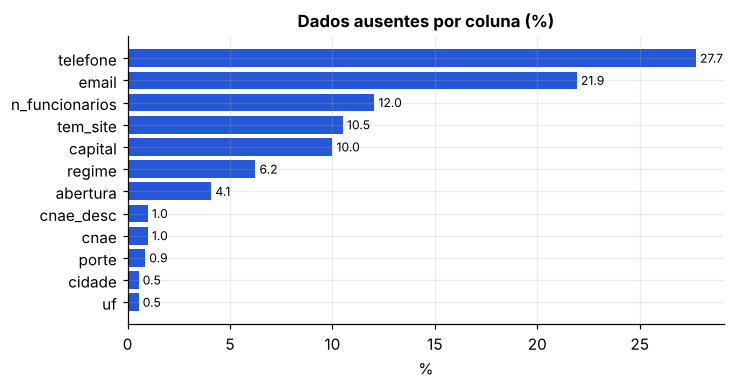

In [3]:
nulls = quality[quality['nulos_%'] > 0]['nulos_%'].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(nulls.index, nulls.values, color=ACC)
ax.set(title='Dados ausentes por coluna (%)', xlabel='%')
for i, v in enumerate(nulls.values): ax.text(v + .2, i, f'{v:.1f}', va='center', fontsize=8)
plt.show()

Parte dos nulos é **MNAR** (não aleatória): MEIs têm mais lacunas em `abertura` e `capital`. Isso importa — tratar ausência como "pior valor" penalizaria sistematicamente empresas pequenas. Por isso o score do ICP mostra o critério como **desconhecido** e o modelo recebe um **indicador de dado ausente**.

Ausência de capital por porte (%):


,capital ausente %
porte,
EPP,4.30
Grande,4.40
ME,12.20
MEI,11.60
Médio,4.40
NaN,10.50


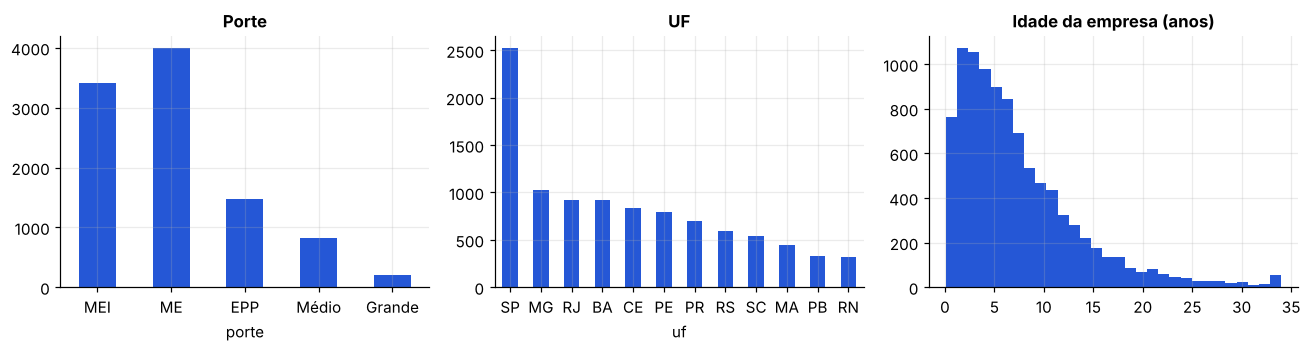

In [4]:
print('Ausência de capital por porte (%):')
display(companies.groupby('porte', dropna=False)['capital'].apply(lambda s: s.isna().mean() * 100).round(1).to_frame('capital ausente %'))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
companies['porte'].value_counts().reindex(['MEI','ME','EPP','Médio','Grande']).plot.bar(ax=axes[0], color=ACC, rot=0)
axes[0].set_title('Porte')
companies['uf'].value_counts().plot.bar(ax=axes[1], color=ACC, rot=0); axes[1].set_title('UF')
age = (pd.Timestamp('2026-11-01') - pd.to_datetime(companies['abertura'])).dt.days / 365.25
axes[2].hist(age.dropna(), bins=30, color=ACC); axes[2].set_title('Idade da empresa (anos)')
plt.tight_layout(); plt.show()

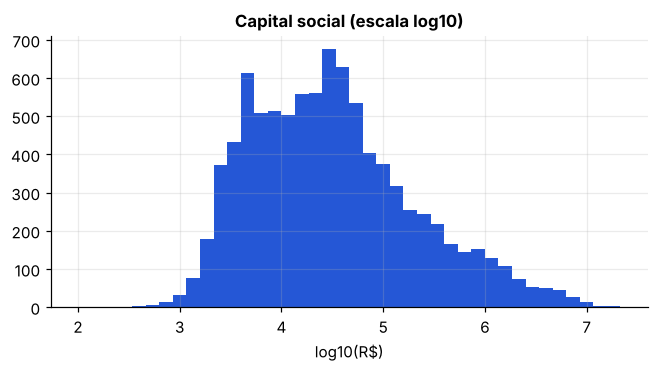

,%
situacao,
Ativa,86.90
Baixada,9.10
Suspensa,3.90


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
cap = companies['capital'].dropna()
ax.hist(np.log10(cap), bins=40, color=ACC)
ax.set(title='Capital social (escala log10)', xlabel='log10(R$)')
plt.show()
companies['situacao'].value_counts(normalize=True).mul(100).round(1).to_frame('%')

## 2. Aderência ao ICP (score por regras)

O score (0–100) é determinístico e auditável. A mesma regra existe em três implementações — `scoring.js` (front), `backend/scoring.py` (pandas) e `backend/sql/search.sql` (SQL) — e os testes garantem que dão **exatamente** o mesmo resultado.

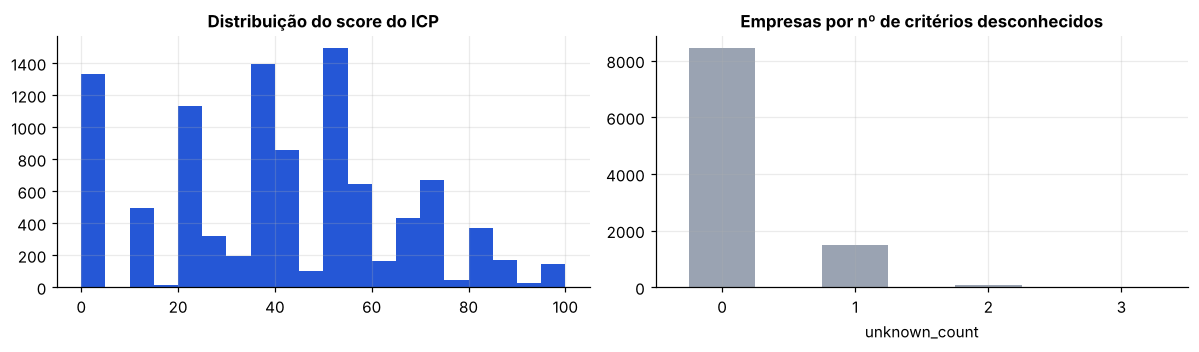

Empresas com score >= 70: 1425 (14.2%)


In [6]:
sc = score_frame(companies, DEFAULT_ICP)
companies_sc = companies.join(sc[['score', 'unknown_count']])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].hist(sc['score'], bins=20, color=ACC); axes[0].set_title('Distribuição do score do ICP')
(companies_sc.groupby('unknown_count').size()).plot.bar(ax=axes[1], color=GREY, rot=0)
axes[1].set_title('Empresas por nº de critérios desconhecidos')
plt.tight_layout(); plt.show()
print('Empresas com score >= 70:', (sc['score'] >= 70).sum(), f"({(sc['score'] >= 70).mean():.1%})")

## 3. Métricas comerciais em SQL

As consultas ficam em `backend/sql/metrics.sql` (CTEs, `LAG`, `FIRST_VALUE`, `RANK`, `LEAD`, `SUM() OVER`, `ROW_NUMBER`). Abaixo, o funil e a aceitação por vendedor.

,stage,deals,conv_etapa_anterior,conv_total
0,Novo,1500,NaN,100.00
1,Contato,1215,81.00,81.00
2,Reunião,619,50.90,41.30
3,Proposta,361,58.30,24.10
4,Ganho,172,47.60,11.50


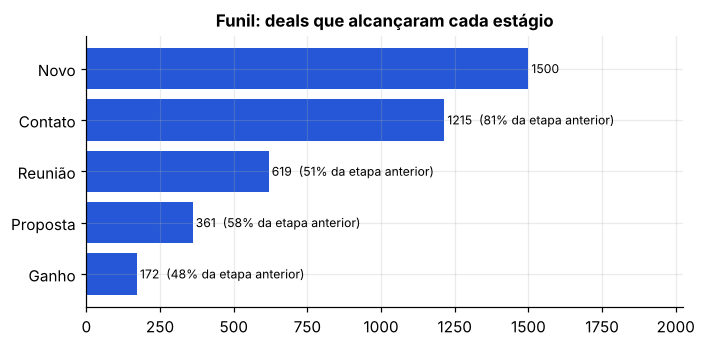

In [7]:
funnel = pd.DataFrame(db.run_named(con, 'funnel'))
display(funnel)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(funnel['stage'][::-1], funnel['deals'][::-1], color=ACC)
for i, (d, c) in enumerate(zip(funnel['deals'][::-1], funnel['conv_etapa_anterior'][::-1])):
    ax.text(d + 10, i, f'{d}' + ('' if pd.isna(c) else f'  ({c:.0f}% da etapa anterior)'), va='center', fontsize=8)
ax.set(title='Funil: deals que alcançaram cada estágio'); ax.set_xlim(0, funnel['deals'].max() * 1.35)
plt.show()

,vendedor,aceitas,rejeitadas,ignoradas,total,taxa_aceitacao,ranking,media_equipe
0,Bruno,255,85,520,860,75.00,1,70.60
1,Elisa,208,84,578,870,71.20,2,70.60
2,Ana,201,89,590,880,69.30,3,70.60
3,Carla,201,89,541,831,69.30,3,70.60
4,Diego,206,97,527,830,68.00,5,70.60


,faixa,deals,ganhos,taxa_ganho
0,80-100,107,41,38.30
1,60-79,169,37,21.90
2,40-59,389,35,9.00
3,0-39,406,19,4.70


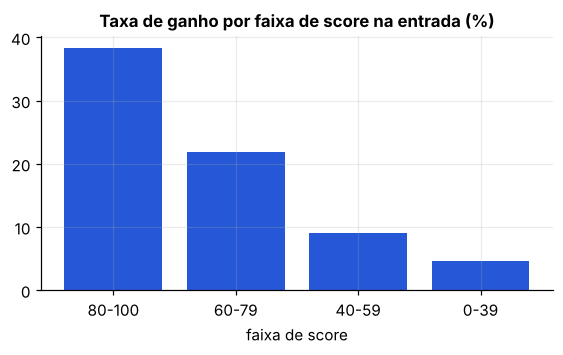

In [8]:
sellers = pd.DataFrame(db.run_named(con, 'sellers'))
display(sellers)
bands = pd.DataFrame(db.run_named(con, 'score_bands'))
display(bands)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(bands['faixa'], bands['taxa_ganho'], color=ACC)
ax.set(title='Taxa de ganho por faixa de score na entrada (%)', xlabel='faixa de score')
plt.show()

> A taxa de ganho cresce com o score, mas isso é **correlação**: nesta base sintética os clientes foram gerados por variáveis parecidas com as do ICP. Em produção, seria preciso um experimento (por exemplo, A/B por carteira) para afirmar impacto causal.

## 4. Lookalike (US-09)

**Problema:** dado o conjunto de clientes conquistados, ranquear as demais empresas por semelhança.
**Modelo:** regressão logística (explicável) com tratamento de ausentes e *one-hot* nas categóricas. Comparação com gradiente boosting e com o score por regras do ICP.
**Validação:** 5-fold estratificado; as métricas usam predições *out-of-fold* (nenhuma empresa é pontuada por um modelo que a viu no treino).

In [9]:
df = lk.load_frame()
y = df['y'].to_numpy()
print(f'Universo (empresas ativas): {len(df):,} | clientes: {y.sum()} | prevalência: {y.mean():.1%}')
ev = lk.evaluate(df)
rows = {'Regressão logística': 'logistic', 'Gradiente boosting': 'boosting', 'Regras do ICP': 'icp_rules_baseline'}
table = pd.DataFrame({n: ev['metrics'][k] for n, k in rows.items()}).T[['auc','average_precision','precision@100','precision@500','lift@100','recall@500']]
table.loc['Acaso'] = [0.5, y.mean(), y.mean(), y.mean(), 1.0, 500 * y.mean() / y.sum()]
table

Universo (empresas ativas): 8,694 | clientes: 505 | prevalência: 5.8%


,auc,average_precision,precision@100,precision@500,lift@100,recall@500
Regressão logística,0.75,0.17,0.24,0.23,4.13,0.23
Gradiente boosting,0.73,0.14,0.24,0.19,4.13,0.18
Regras do ICP,0.73,0.15,0.24,0.23,4.13,0.23
Acaso,0.50,0.06,0.06,0.06,1.00,0.06


AUC por fold: 0.750 ± 0.016


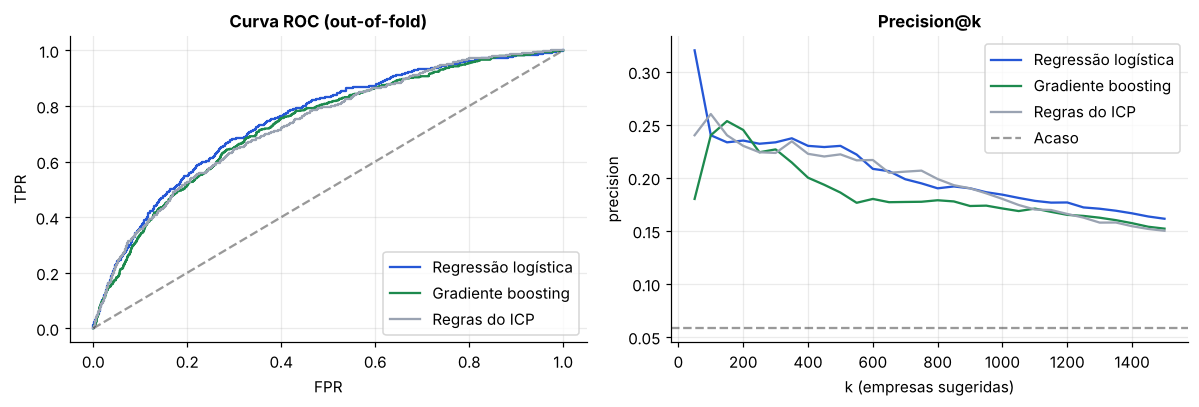

In [10]:
m = ev['metrics']['logistic']
print(f"AUC por fold: {m['auc_folds_mean']:.3f} ± {m['auc_folds_std']:.3f}")

rules = score_frame(df, DEFAULT_ICP)['score'].to_numpy() + np.random.default_rng(0).random(len(df)) * 1e-6
scores = {'Regressão logística': ev['oof']['logistic'], 'Gradiente boosting': ev['oof']['boosting'], 'Regras do ICP': rules}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, s), col in zip(scores.items(), [ACC, '#1d8a4e', GREY]):
    fpr, tpr, _ = roc_curve(y, s); axes[0].plot(fpr, tpr, label=name, color=col)
    ks = np.arange(50, 1501, 50); axes[1].plot(ks, [lk.precision_at_k(y, s, k) for k in ks], label=name, color=col)
axes[0].plot([0, 1], [0, 1], '--', color='k', alpha=.4); axes[0].set(title='Curva ROC (out-of-fold)', xlabel='FPR', ylabel='TPR'); axes[0].legend()
axes[1].axhline(y.mean(), ls='--', color='k', alpha=.4, label='Acaso'); axes[1].set(title='Precision@k', xlabel='k (empresas sugeridas)', ylabel='precision'); axes[1].legend()
plt.tight_layout(); plt.show()

**Leitura honesta dos resultados.** O modelo supera o acaso com folga (lift de ~4× nas 100 primeiras sugestões) e é estável entre folds, mas supera o score por regras apenas **marginalmente**. É esperado: o ICP padrão foi desenhado com os mesmos sinais que geram os rótulos simulados (CNAE, região, porte). O ganho do ML tende a aparecer quando houver sinais que as regras não capturam e muito mais dados reais. Gradiente boosting não superou a logística, o que reforça a escolha por um modelo simples e explicável.

### Explicabilidade

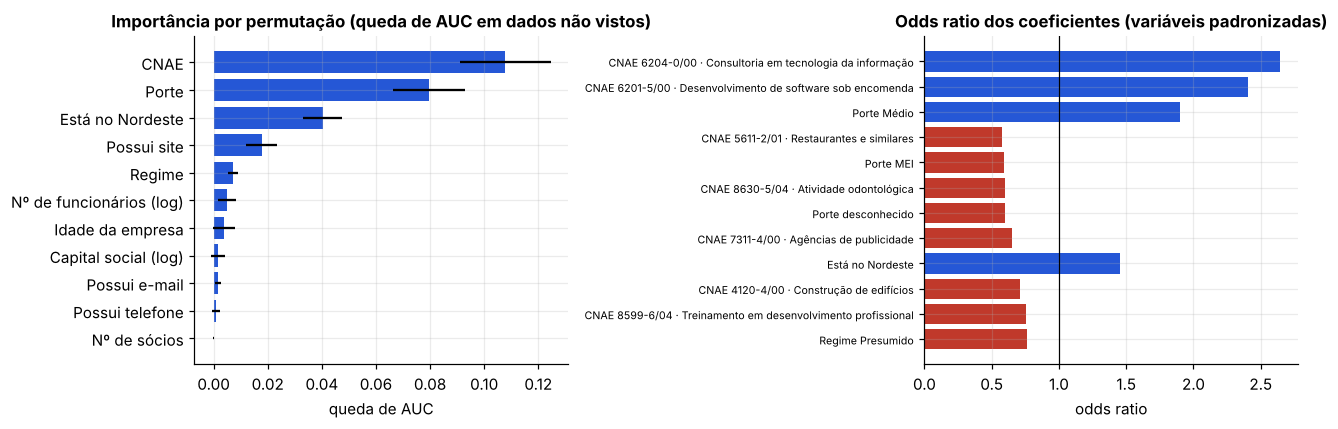

In [11]:
final = lk.logistic().fit(lk.make_features(df), y)
exp = lk.explain(df, final)
perm = pd.DataFrame(exp['permutation_importance'])
coef = pd.DataFrame(exp['coefficients']).head(12)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(perm['feature'][::-1], perm['auc_drop'][::-1], xerr=perm['std'][::-1], color=ACC)
axes[0].set(title='Importância por permutação (queda de AUC em dados não vistos)', xlabel='queda de AUC')
colors = [ACC if c > 0 else '#c0392b' for c in coef['coef'][::-1]]
axes[1].barh(coef['feature'][::-1], coef['odds_ratio'][::-1], color=colors); axes[1].axvline(1, color='k', lw=.8)
axes[1].set(title='Odds ratio dos coeficientes (variáveis padronizadas)', xlabel='odds ratio')
axes[1].tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

As variáveis mais importantes (CNAE, porte, região) coincidem com os termos usados para **gerar** os rótulos — uma checagem de sanidade: o modelo recuperou a estrutura conhecida. Em dados reais não existe essa verdade para comparar, então a explicabilidade serve para auditar o modelo com quem conhece o mercado.

### Sugestões com justificativa

In [12]:
top = pd.read_sql('''
  SELECT c.nome, c.uf, c.porte, c.cnae_desc, ROUND(l.score, 3) AS prob, l.reasons
  FROM lookalike_scores l JOIN companies c USING (cnpj)
  WHERE l.cnpj NOT IN (SELECT cnpj FROM customers)
  ORDER BY l.score DESC LIMIT 8''', con)
top['por_que'] = top['reasons'].apply(lambda s: ' · '.join(r['feature'] for r in json.loads(s)))
top.drop(columns='reasons')

,nome,uf,porte,cnae_desc,prob,por_que
0,Cobalto Partners 05867,BA,Médio,Consultoria em tecnologia da informação,0.52,CNAE 6204-0/00 · Consultoria em tecnologia da ...
1,Prisma Soluções 07588,PE,Médio,Desenvolvimento de software sob encomenda,0.52,CNAE 6201-5/00 · Desenvolvimento de software s...
2,Delta Labs 09892,PB,Médio,Desenvolvimento de software sob encomenda,0.51,CNAE 6201-5/00 · Desenvolvimento de software s...
3,Faísca Digital 04348,BA,Médio,Desenvolvimento de software sob encomenda,0.46,CNAE 6201-5/00 · Desenvolvimento de software s...
4,Névoa Soluções 00486,CE,Grande,Consultoria em tecnologia da informação,0.46,CNAE 6204-0/00 · Consultoria em tecnologia da ...
5,Quasar Serviços 00480,MA,Grande,Desenvolvimento de software sob encomenda,0.46,CNAE 6201-5/00 · Desenvolvimento de software s...
6,Prisma Soluções 03496,MA,Médio,Consultoria em tecnologia da informação,0.45,CNAE 6204-0/00 · Consultoria em tecnologia da ...
7,Brisa Soluções 01429,BA,Médio,Desenvolvimento de software sob encomenda,0.45,CNAE 6201-5/00 · Desenvolvimento de software s...


## 5. Limitações e próximos passos

- **Rótulos simulados:** os números não valem para dados reais; servem para validar o pipeline.
- **Sem séries temporais:** a validação é aleatória (k-fold). Com dados reais, preferir validação temporal para evitar vazamento.
- **Viés de seleção:** clientes reais refletem quem a equipe já prospectou; um lookalike pode reproduzir esse viés. Vale medir cobertura de segmentos pouco explorados.
- **Calibração e custo:** se as probabilidades forem exibidas ao usuário, calibrar (Platt/isotônica) e comunicar como "semelhança", não "chance de compra".
- **Privacidade:** usar dados de CRM de um cliente para recomendar a outro exige base legal e controles; o modelo deve ser treinado **por tenant**.
- **Próximos passos:** monitorar *drift*, comparar com *embeddings* de descrição de atividade e medir impacto com teste A/B.